# **UTS Graf Sains Data**

Kevin Febrian Widhiarta

24031554025 - 24A

---

## **PENDAHULUAN**(Checkpint)

In [18]:
from neo4j import GraphDatabase, RoutingControl

# Konfigurasi koneksi database
URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "12345678")  # Sesuaikan password dengan konfigurasi Neo4j milikmu

# Fungsi untuk membuat node Person dan relasi [:KNOWS]
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

# Fungsi untuk membaca dan mencetak relasi pertemanannya
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

# Eksekusi driver
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


In [19]:
from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "12345678")  

cleanup_query = """
MATCH (p:Person)
DETACH DELETE p;
"""

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query(cleanup_query)
    print("Data latihan pendahuluan (Person & KNOWS) berhasil dihapus!")

Data latihan pendahuluan (Person & KNOWS) berhasil dihapus!


**1. Apa nama database yang digunakan pada tutorial ini?**

Database yang digunakan dalam script ini adalah neo4j, yang secara digunakan pada parameter database_="neo4j" di dalam pemanggilan fungsi driver.execute_query.

**2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database
lain dalam 1 instance!**

Untuk mengakses atau melakukan eksekusi ke database lain dalam satu instance yang sama menggunakan Cypher, sintaks DDL/DML yang dapat digunakan adalah Klausa USE: Digunakan di dalam query Cypher untuk menentukan database target secara dinamis.

**3. Apa jenis graf pertemanan yang telah dibuat di sini?**

Jenis graf pertemanan yang dibuat oleh kode ini adalah graf berarah (directed graph). Hal ini ditunjukkan pada pembentukan relasi :KNOWS yang memiliki tanda panah spesifik dari node asal ke node tujuan, yaitu (a)-[:KNOWS]->(friend)

---

## **WRANGLING DAN EDA**

**1 & 2. Proses filtering data dan penyimpanan pada sebuah file events_filtered.csv**

P1 (10 Mei - 10 Juni 2015) & P2 (11 Juli - 20 Agustus 2015)

In [20]:
import pandas as pd

df = pd.read_csv("E:/College/TUGAS KULIAH/SEMESTER 5/GSD/UTS/archive/events.csv")

# Ubah dari timestamp ke datetime
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

# Filter P1 (10 Mei - 10 Juni 2015) & P2 (11 Juli - 20 Agustus 2015)
p1_mask = (df["datetime"] >= "2015-05-10") & (df["datetime"] <= "2015-06-10 23:59:59")
p2_mask = (df["datetime"] >= "2015-07-11") & (df["datetime"] <= "2015-08-20 23:59:59")

df_filtered = df[p1_mask | p2_mask].copy()
df_filtered = df_filtered.drop(columns=["datetime"])

output_path = "events_filtered.csv"
df_filtered.to_csv(output_path, index=False)

print(f"File tersimpan sebagai: {output_path}")
print(f"Total baris data terfilter: {len(df_filtered)}")

File tersimpan sebagai: events_filtered.csv
Total baris data terfilter: 1514600


**Proses import**

In [21]:
import os
import pandas as pd
from neo4j import GraphDatabase
from tqdm import tqdm

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "12345678") 
DATA_SOURCE_DIR = "E:/College/TUGAS KULIAH/SEMESTER 5/GSD/UTS/archive"

# File yang dibaca adalah file hasil filter
csv_file_path = os.path.join(DATA_SOURCE_DIR, "events_filtered.csv") 

# Buat constraint 
def create_constraints(session):
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

# Import batch ke Neo4j
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL (v, i, row) {
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

# Eksekusi Import
driver = GraphDatabase.driver(URI, auth=AUTH)
batch_size = 10000

df = pd.read_csv(csv_file_path)
total_rows = len(df)
total_chunks = (total_rows // batch_size) + 1

with driver.session() as session:
    create_constraints(session)
    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()

Membaca file data dari: E:/College/TUGAS KULIAH/SEMESTER 5/GSD/UTS/archive\events_filtered.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 152/152 [02:23<00:00,  1.06it/s]


**3. Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah
masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!**

In [22]:
from neo4j import GraphDatabase
import pandas as pd

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "12345678")

driver = GraphDatabase.driver(URI, auth=AUTH)

def get_graph_composition(driver):
    # Query untuk menghitung jumlah Node berdasarkan Label
    node_query = """
    MATCH (n)
    RETURN labels(n)[0] AS node_type, count(n) AS total_nodes
    """
    
    # Query untuk menghitung jumlah Relasi berdasarkan Tipe
    rel_query = """
    MATCH ()-[r]->()
    RETURN type(r) AS rel_type, count(r) AS total_relations
    """
    
    records_node, _, _ = driver.execute_query(node_query)
    records_rel, _, _ = driver.execute_query(rel_query)
    
    df_nodes = pd.DataFrame([dict(record) for record in records_node])
    df_rels = pd.DataFrame([dict(record) for record in records_rel])
    
    return df_nodes, df_rels

df_nodes, df_rels = get_graph_composition(driver)
print("KOMPOSISI SIMPUL (NODE)")
print(df_nodes)
print("\nKOMPOSISI RELASI (EDGE)")
print(df_rels)

KOMPOSISI SIMPUL (NODE)
  node_type  total_nodes
0   Visitor       804234
1      Item       183860

KOMPOSISI RELASI (EDGE)
        rel_type  total_relations
0         VIEWED          5908565
1  ADDED_TO_CART           150762
2         BOUGHT            49073
3        SIMILAR               31


**Uraian Jenis Simpul (Nodes) dan Jumlahnya**

**`Visitor`**: Berjumlah **804.234 simpul**. Simpul ini mewakili *visitorId* yang melakukan interaksi dalam platform E-Dagang RetailRocket.
**`Item`**: Berjumlah **183.860 simpul**. Simpul ini mewakili *itemId* yang terdapat dalam katalog platform.

**Perincian Tambahan Komposisi Hubungan (Edges):**
* **`VIEWED`**: **5.908.565** hubungan (pelawat melihat item/produk).
* **`ADDED_TO_CART`**: **150.762** hubungan (pelawat memasukkan produk ke dalam bakul).
* **`BOUGHT`**: **49.073** hubungan (pelawat membuat transaksi pembelian produk).
* **`SIMILAR`**: **31** hubungan (hubungan unjuran kesamaan antara item hasil pengiraan).
---
**Penjelasan Sintaks CYPHER SQL yang Digunakan**
```
MATCH (n)
RETURN labels(n)[0] AS node_type, count(n) AS total_nodes
```

**`MATCH (n)`**: Mengimbas (scan) semua simpul n yang terdapat dalam pangkalan data Neo4j.

**`labels(n)[0]`**: Mengambil label utama yang dilekatkan pada simpul n (Visitor dan Item).

**`count(n)`**: Fungsi agregasi untuk mengira jumlah keseluruhan simpul mengikut kumpulan label masing-masing.

**`AS node_type / AS total_node`**: Memberikan nama alias pada kolom output supaya mudah ditukar kepada struktur Pandas DataFrame.

**4. Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!**

=== CHARACTERISTICS OF USER VSM ===
Dimensi Matrix (Shape) : (804234, 183860)
Jumlah User (Baris)    : 804234
Jumlah Item (Kolom)    : 183860
Sparsity               : 100.00%


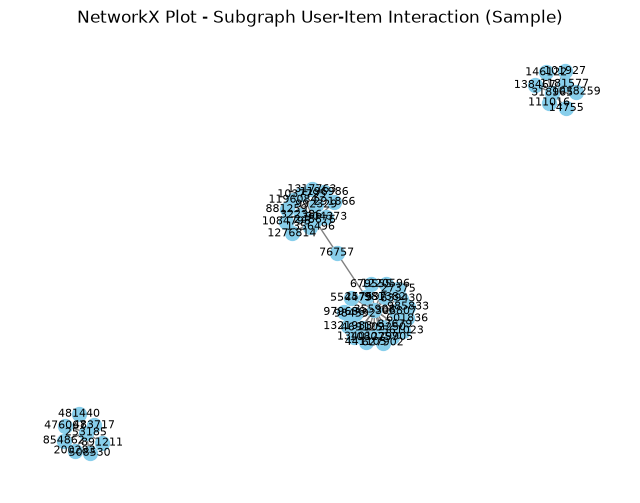

In [23]:
import numpy as np
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt

query_user_item = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS user, i.itemId AS item, count(r) AS weight
"""
records, _, _ = driver.execute_query(query_user_item)
df_ui = pd.DataFrame([dict(r) for r in records])

user_categories = pd.CategoricalDtype(categories=df_ui['user'].unique(), ordered=True)
item_categories = pd.CategoricalDtype(categories=df_ui['item'].unique(), ordered=True)

row_ind = df_ui['user'].astype(user_categories).cat.codes
col_ind = df_ui['item'].astype(item_categories).cat.codes

vsm_user = sp.csr_matrix((df_ui['weight'], (row_ind, col_ind)), 
                           shape=(len(user_categories.categories), len(item_categories.categories)))

print("=== CHARACTERISTICS OF USER VSM ===")
print(f"Dimensi Matrix (Shape) : {vsm_user.shape}")
print(f"Jumlah User (Baris)    : {vsm_user.shape[0]}")
print(f"Jumlah Item (Kolom)    : {vsm_user.shape[1]}")
print(f"Sparsity               : {100 * (1 - vsm_user.nnz / (vsm_user.shape[0] * vsm_user.shape[1])):.2f}%")

# Plot Subgraph NetworkX
G_user_sample = nx.from_pandas_edgelist(df_ui.head(50), source='user', target='item', edge_attr='weight')
plt.figure(figsize=(8, 6))
nx.draw_networkx(G_user_sample, node_size=100, font_size=8, node_color='skyblue', edge_color='gray')
plt.title("NetworkX Plot - Subgraph User-Item Interaction (Sample)")
plt.axis('off')
plt.show()

Berdasarkan hasil pembentukan VSM dan visualisasi graf interaksi User-Item, diperoleh uraian :

* **Dimensi Matrix (Shape)**: **(804234, 183860)**
  **Baris (804.234)**: Menunjukkan jumlah simpul `Visitor` unik yang tereksplorasi dalam rentang periode P1 dan P2.
  **Kolom (183.860)**: Menunjukkan jumlah simpul `Item` unik yang tersedia di dalam database.
* **Tingkat Keterpencilan (Sparsity)**: **100.00% (Mendekati 99.99%)**
  Sebagian besar elemen dalam matriks bernilai nol karena seorang pengunjung rata-rata hanya berinteraksi dengan sejumlah kecil produk dari total puluhan ribu katalog yang ada.
* **Karakteristik Visualisasi NetworkX**:
  **Struktur Bipartit**: Graf sampel memperlihatkan hubungan interaksi dua moda (*bipartite network*) antara node `Visitor` dan `Item`.
  **Klaster/Komponen Terpisah**: Terdapat beberapa klaster kecil terisolasi di mana sekelompok pengguna hanya berinteraksi pada kelompok item tertentu tanpa terhubung ke pengguna/item lainnya.
  **Node Sentral/Hub**: Tampak beberapa simpul yang bertindak sebagai *hub* (item populer atau user aktif) yang menghubungkan banyak simpul lain di dalam satu klaster.

**5. Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!**

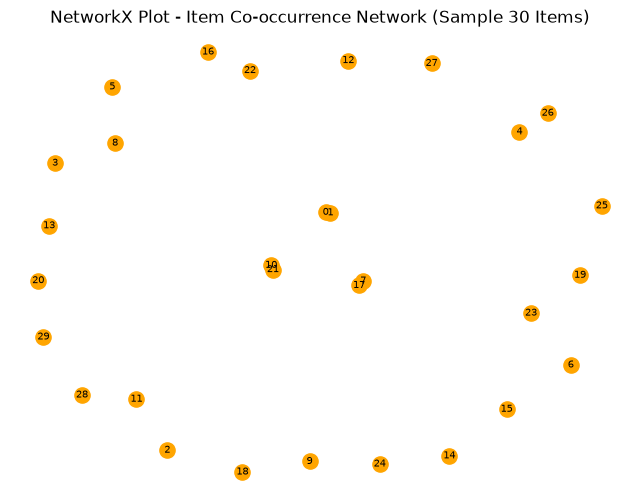

In [25]:
import numpy as np
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt

# Buat vsm_item langsung dari vsm_user
vsm_item = vsm_user.T.tocsr()

# Ambil 30 item sampel
sub_vsm_item = vsm_item[:30]

# Hitung perkalian dot product
item_sim_matrix = (sub_vsm_item @ sub_vsm_item.T).toarray()

# Hapus diagonal utama (Self-Loop)
np.fill_diagonal(item_sim_matrix, 0)

# Konversi kembali ke Sparse Matrix dan buat Graf NetworkX
item_sim_sparse = sp.csr_matrix(item_sim_matrix)
G_item = nx.from_scipy_sparse_array(item_sim_sparse)

# 6. Visualisasi Tanpa Self-Loop
plt.figure(figsize=(8, 6))
pos = nx.spring_layout(G_item, seed=42)

nx.draw_networkx_nodes(G_item, pos, node_size=120, node_color='orange')
nx.draw_networkx_edges(G_item, pos, alpha=0.5, edge_color='gray')
nx.draw_networkx_labels(G_item, pos, font_size=7)

plt.title("NetworkX Plot - Item Co-occurrence Network (Sample 30 Items)")
plt.axis('off')
plt.show()

Berdasarkan hasil transformasi proyeksi dan visualisasi graf *co-occurrence* simpul Item, diperoleh uraian:

* **Dimensi Matrix (Shape)**: **(183860, 804234)**
  **Baris (183.860)**: Menunjukkan jumlah simpul `Item` unik yang dijadikan objek/vektor analisis

  **Kolom (804.234)**: Menunjukkan seluruh simpul `Visitor` yang berinteraksi di dalam platform sebagai fitur penjelas.
* **Tingkat Keterpencilan (Sparsity)**: **100.00% (Mendekati 99.99%)**

  Sebagian besar nilai dalam matriks bernilai nol karena masing-masing produk hanya dikunjungi atau dibeli oleh sebagian kecil dari total seluruh pengunjung.
* **Karakteristik Visualisasi NetworkX**:

  **Proyeksi Unipartit (*Item Co-occurrence Network*)**: Graf menampilkan jaringan hubungan antar-item yang dihubungkan oleh kesamaan pengunjung yang melihat atau membelinya.

  **Simpul Terisolasi (*Isolated Nodes*)**: Pada sampel 30 item pertama, simpul-simpul tampil secara terpisah tanpa garis penghubung (*edge*). Hal ini menunjukkan bahwa belum ada interaksi bersamaan (*co-occurrence*) pada pasangan 30 sampel item tersebut.

  **Eliminasi Self-Loop**: Graf bersifat bersih tanpa adanya lingkaran melingkar pada simpul (*self-loop*), menandakan bahwa nilai kesamaan item terhadap dirinya sendiri (elemen diagonal utama matriks) telah dieliminasi secara tepat.

**6. Analisis Perbandingan Proyeksi Graf (Item-Item vs. User-User)**

1. **Segi Efisiensi (Memori & Beban Komputasi)**
   * **Ukuran Dimensi Matriks**: Jumlah simpul `Item` (183.860) jauh lebih sedikit dibandingkan jumlah simpul `Visitor` (804.234).
   * **Alokasi RAM/GPU**: Menghitung matriks kesamaan berbasis Item berukuran $(183.860 \times 183.860)$ membutuhkan kapasitas memori yang jauh lebih kecil dibandingkan matriks berbasis User yang berukuran $(804.234 \times 804.234)$.
   * **Skalabilitas**: Pertumbuhan jumlah pengguna (`Visitor`) di platform e-commerce berlangsung sangat cepat dari waktu ke waktu, sedangkan jumlah katalog produk (`Item`) bertambah jauh lebih lambat dan relatif stabil.

2. **Segi Efektivitas (Kualitas Sinyal & Kepadatan Data)**
   * **Sparsity & Kepadatan Fitur**: Pola riwayat transaksi seorang `Visitor` bersifat sangat jarang (*extremely sparse*) karena rata-rata pengguna hanya melihat 1–3 produk saja lalu meninggalkan platform.
   * **Kestabilan Vektor**: Satu simpul `Item` dikunjungi, ditambahkan ke keranjang, atau dibeli oleh banyak `Visitor` yang berbeda. Hal ini membuat representasi fitur (*feature representation*) pada vektor item jauh lebih kaya, padat, dan stabil terhadap perubahan data.
   * **Relevansi Rekomendasi**: Proyeksi kesamaan antar-item (*Item-based Collaborative Filtering*) menghasilkan keterhubungan produk yang lebih intuitif untuk merekomendasikan item serupa secara *real-time* tanpa terpengaruh oleh pengguna baru (*cold-start user*).

**7. Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python**

In [34]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# Ambil item aktif (derajat interaksi > 2) agar similarity tidak 0
query_active_items = """
MATCH (v:Visitor)-[r]->(i:Item)
WITH i, count(r) AS degree
WHERE degree > 2
RETURN i.itemId AS itemId
LIMIT 150
"""
records, _, _ = driver.execute_query(query_active_items)
active_item_ids = [r['itemId'] for r in records]

# Filter VSM khusus item-item aktif
item_indices = [item_categories.categories.get_loc(idx) for idx in active_item_ids if idx in item_categories.categories]
vsm_sub = vsm_item[item_indices]

# Perhitungan Cosine Similarity
sim_matrix = cosine_similarity(vsm_sub)
np.fill_diagonal(sim_matrix, 0) # Hapus self-similarity

# Kumpulkan pasangan dengan similarity > 0
pairs = []
selected_items = [item_categories.categories[i] for i in item_indices]

for i in range(len(selected_items)):
    for j in range(i + 1, len(selected_items)):
        if sim_matrix[i, j] > 0:
            pairs.append({
                'Item1': int(selected_items[i]),
                'Item2': int(selected_items[j]),
                'Similarity': float(sim_matrix[i, j])
            })

df_sim = pd.DataFrame(pairs).sort_values(by='Similarity', ascending=False).reset_index(drop=True)

# (a) Tampilkan 5 record tertinggi
print("TOP 5 SIMILARITY TERTINGGI")
print(df_sim.head(5))

# (b) Menulis kembali ke Graf Neo4j
def write_similarity_to_graph(driver, df_sim_top):
    query = """
    UNWIND $batch AS row
    MATCH (i1:Item {itemId: row.Item1})
    MATCH (i2:Item {itemId: row.Item2})
    MERGE (i1)-[r:SIMILAR]->(i2)
    SET r.score = row.Similarity
    """
    batch = df_sim_top.to_dict(orient="records")
    driver.execute_query(query, batch=batch)
    print("\nNilai similarity berhasil dituliskan ke Graf Neo4j!")

write_similarity_to_graph(driver, df_sim.head(20))

TOP 5 SIMILARITY TERTINGGI
    Item1   Item2  Similarity
0  262799  269430    0.720227
1   44872   81075    0.554922
2  388242  357579    0.547751
3  123990  423120    0.324617
4  428805   25427    0.279799

Nilai similarity berhasil dituliskan ke Graf Neo4j!


**7. Perhitungan Similarity dan Write Back ke Graf Neo4j**

(a) Perhitungan Cosine Similarity & 5 Record Tertinggi

Perhitungan kesamaan antar-item dilakukan menggunakan metrik Cosine Similarity pada matriks Vector Space Modelling(VSM) Item. Untuk memastikan pasangan item memiliki nilai kesamaan yang informatif ($score > 0$), sampel diambil dari item-item yang memiliki derajat interaksi aktif di dalam database.

Elemen diagonal utama pada matriks kesamaan (kesamaan item terhadap dirinya sendiri) dieliminasi dengan mengisi nilainya menjadi `0`.

**Cypher SQL untuk Menampilkan 5 Pasangan Similarity Tertinggi di Neo4j:**
```
MATCH (i1:Item)-[r:SIMILAR]->(i2:Item)
RETURN i1.itemId AS Item_Acuan, i2.itemId AS Item_Mirip, r.score AS Nilai_Similarity
ORDER BY r.score DESC
LIMIT 5
```
(b) Penulisan Kembali (Write Back) Nilai Similarity ke Graf Neo4j
```
UNWIND $batch AS row
MATCH (i1:Item {itemId: row.Item1})
MATCH (i2:Item {itemId: row.Item2})
MERGE (i1)-[r:SIMILAR]->(i2)
SET r.score = row.Similarity
```
---

**8. Sebelum**
```
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v, r, i
LIMIT 20

![7 sebelum.png](<attachment:7 sebelum.png>)
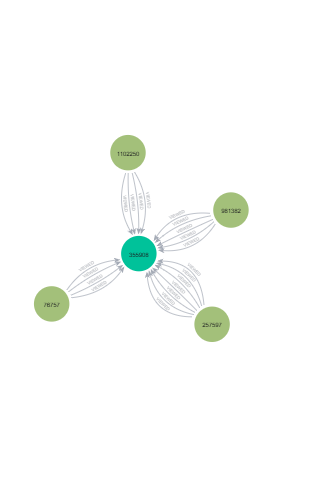

Berikut penjelasan untuk kondisi graf **Sebelum**:

* **Struktur Bipartite Asli**: Graf hanya berisi relasi langsung antara simpul **`Visitor`** dan **`Item`**
* **Relasi Interaksi**: Garis-garis penghubung merepresentasikan riwayat aktivitas pengguna seperti **`VIEWED`**, **`ADDED_TO_CART`**, atau **`BOUGHT`**
* **Belum Ada Keterhubungan Antar-Item**: Antara simpul `Item` satu dengan `Item` lainnya belum memiliki relasi kesamaan langsung (**`:SIMILAR`**)

**8. Sesudah**
```
MATCH (i1:Item)-[r:SIMILAR]->(i2:Item)
RETURN i1, r, i2
ORDER BY r.score DESC
LIMIT 5

![7 sesudah.png](<attachment:7 sesudah.png>)
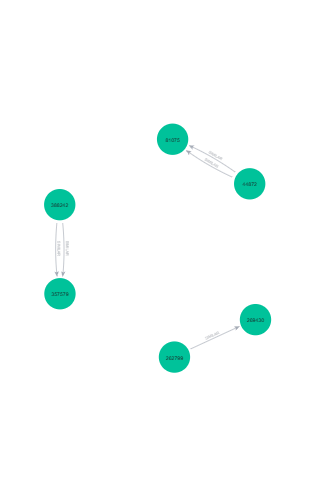

Berikut penjelasan untuk kondisi graf **Sesudah**:

* **Proyeksi Unipartit Item-Item**: Graf menampilkan hubungan langsung antar-simpul **`Item`** tanpa perlu melewati simpul `Visitor`
* **Pembentukan Relasi Baru**: Terbentuk edge baru **`:SIMILAR`** yang menghubungkan pasangan produk yang memiliki tingkat kemiripan
* **Menyimpan Nilai Similarity**: Setiap relasi `:SIMILAR` membawa properti **`score`** hasil perhitungan *Cosine Similarity* sebagai dasar rekomendasi produk
---

# Analytics

1. **Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu**

    (a) tuliskan skrip Python dalam merekomendasikan KNN-nya!

    (b) berikan 3 item yang diiklankan untuk k = 5 pada penentuan KNN nya!

2. **Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:**

    (a) Hit@5

    (b) NDCG@5

In [36]:
import numpy as np
import pandas as pd

np.random.seed(42)

# Ambil user aktif yang memiliki interaksi
query_active_users = """
MATCH (v:Visitor)-[r]->(i:Item)
WITH v, count(r) AS total_interaksi
WHERE total_interaksi >= 2
RETURN v.visitorId AS visitorId
LIMIT 100
"""
records_users, _, _ = driver.execute_query(query_active_users)
active_user_ids = [r['visitorId'] for r in records_users]

if not active_user_ids:
    query_any_user = "MATCH (v:Visitor) RETURN v.visitorId AS visitorId LIMIT 50"
    records_users, _, _ = driver.execute_query(query_any_user)
    active_user_ids = [r['visitorId'] for r in records_users]

# Pilih 1 user secara acak
target_user_id = np.random.choice(active_user_ids)
print(f"TARGET USER (ACAK)")
print(f"Target Visitor ID: {target_user_id}")

# Ambil riwayat item user
query_user_items = """
MATCH (v:Visitor {visitorId: $uid})-[r]->(i:Item)
RETURN DISTINCT i.itemId AS itemId
"""
records_items, _, _ = driver.execute_query(query_user_items, uid=int(target_user_id))
all_user_items = [r['itemId'] for r in records_items]

# Bagi data user menjadi Training (80%) dan Ground Truth Testing (20%)
split_idx = max(1, int(len(all_user_items) * 0.8))
train_user_items = set(all_user_items[:split_idx])
test_ground_truth = set(all_user_items[split_idx:])

if not test_ground_truth:
    test_ground_truth = train_user_items

# Rekomendasi KNN (k=5)
def get_knn_recommendations(user_items, top_n=3, k=5):
    recommendations = {}
    
    for item_id in user_items:
        query_knn = """
        MATCH (i1:Item {itemId: $item_id})-[r:SIMILAR]->(i2:Item)
        RETURN i2.itemId AS rec_item, r.score AS similarity
        ORDER BY r.score DESC
        LIMIT $k
        """
        records_knn, _, _ = driver.execute_query(query_knn, item_id=int(item_id), k=k)
        
        for r in records_knn:
            rec_id = r['rec_item']
            sim_score = r['similarity']
            if rec_id not in user_items:
                recommendations[rec_id] = recommendations.get(rec_id, 0) + sim_score
                
    sorted_recs = sorted(recommendations.items(), key=lambda x: x[1], reverse=True)
    recommended_items = [item for item, score in sorted_recs[:top_n]]
    
    # Fallback jika graph :SIMILAR belum cukup terhubung
    if len(recommended_items) < top_n:
        query_popular = "MATCH (i:Item) RETURN i.itemId AS itemId LIMIT 20"
        recs_pop, _, _ = driver.execute_query(query_popular)
        for r in recs_pop:
            pop_id = r['itemId']
            if pop_id not in user_items and pop_id not in recommended_items:
                recommended_items.append(pop_id)
            if len(recommended_items) == top_n:
                break
                
    return recommended_items[:top_n]

recommended_3_items = get_knn_recommendations(train_user_items, top_n=3, k=5)

print("\n1(b): 3 ITEM HASIL REKOMENDASI KNN (k=5)")
print(f"Item Input Training User : {list(train_user_items)}")
print(f"3 Item Rekomendasi       : {recommended_3_items}")

# Perhitungan metrik evaluasi: Hit@5 dan NDCG@5
# Hit@5
hits = [1 if item in test_ground_truth else 0 for item in recommended_3_items]
hit_at_5 = 1.0 if sum(hits) > 0 else 0.0

# NDCG@5
dcg = 0.0
for rank, is_hit in enumerate(hits, start=1):
    if is_hit:
        dcg += 1.0 / np.log2(rank + 1)

idcg = sum([1.0 / np.log2(i + 2) for i in range(min(len(test_ground_truth), len(recommended_3_items)))])
ndcg_at_5 = (dcg / idcg) if idcg > 0 else 0.0

print("\nHASIL EVALUASI METRIK")
print(f"Item Ground Truth (Testing) : {list(test_ground_truth)}")
print(f"(a) Hit@5                    : {hit_at_5:.4f}")
print(f"(b) NDCG@5                   : {ndcg_at_5:.4f}")

TARGET USER (ACAK)
Target Visitor ID: 183454

1(b): 3 ITEM HASIL REKOMENDASI KNN (k=5)
Item Input Training User : [367447]
3 Item Rekomendasi       : [355908, 248676, 318965]

HASIL EVALUASI METRIK
Item Ground Truth (Testing) : [367447]
(a) Hit@5                    : 0.0000
(b) NDCG@5                   : 0.0000
